# Exploratory Data Analysis: S&P 500 Company Fundamentals and Risk

## Research question

> Do changes in EBITDA and market capitalization help explain future volatility and risk-adjusted performance across S&P 500 firms?

## Data scope and limitation

The supplied ZIP contains daily OHLCV stock-price CSVs and symbol metadata. It does **not** contain EBITDA, market capitalization, dated S&P 500 constituent membership, or fundamental change records. The analysis below therefore describes historical price behavior for ten selected symbols (AAPL, MSFT, NVDA, AMZN, GOOGL, JPM, XOM, PG, WMT, KO) from January 2010 through April 2020. It cannot test whether changes in EBITDA or market capitalization explain future outcomes. The selected names may also create survivorship bias; treat these charts as an exploratory price-only baseline.

## Measures

- Adjusted close is used for the price path and daily returns.
- Rolling volatility is the standard deviation of daily returns over 252 trading days, annualized by √252.
- Risk-adjusted return is shown as an annualized Sharpe proxy using a zero risk-free rate. It is a simple historical comparison, not a forecast.


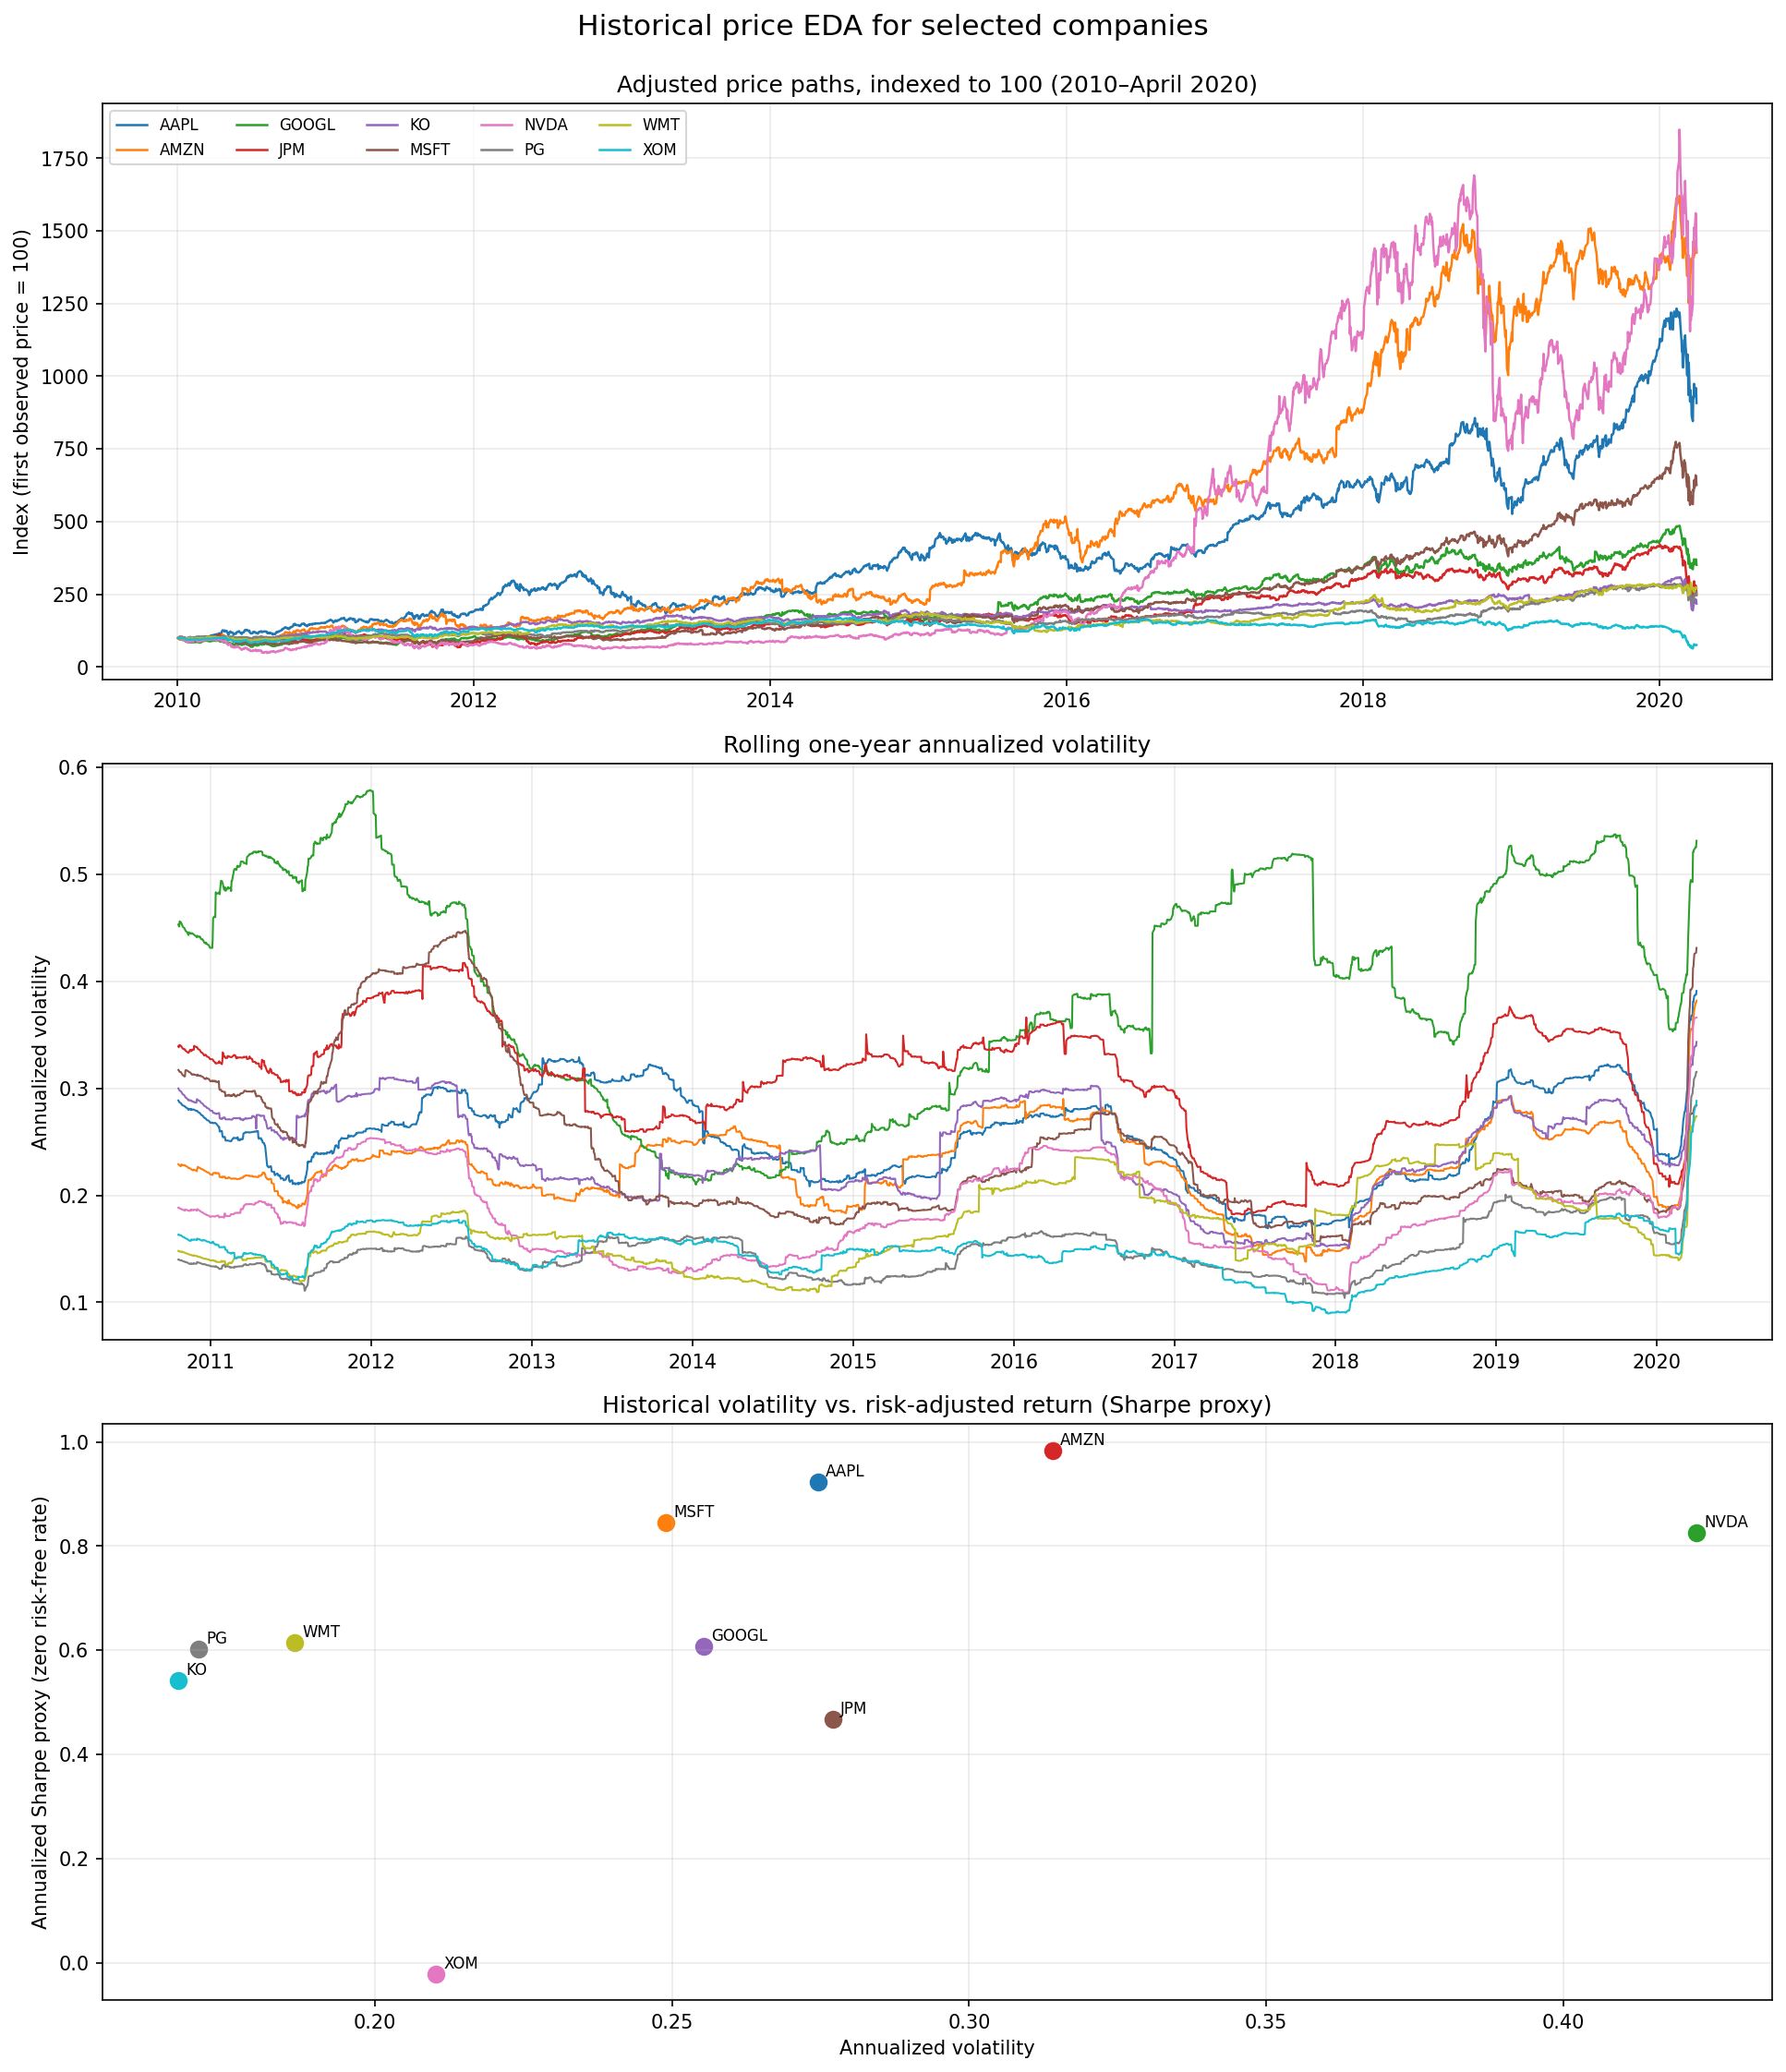

Symbol      CAGR  Volatility  SharpeProxy  Observations
  AAPL  0.240385    0.274604     0.923134          2578
  AMZN  0.296205    0.314018     0.983627          2578
 GOOGL  0.130565    0.255277     0.608269          2578
   JPM  0.095080    0.277080     0.466925          2578
    KO  0.079238    0.166944     0.541254          2578
  MSFT  0.196193    0.248953     0.844981          2578
  NVDA  0.296525    0.422398     0.825124          2578
    PG  0.092107    0.170294     0.602871          2578
   WMT  0.102239    0.186544     0.615363          2578
   XOM -0.026370    0.210308    -0.021396          2578

In [1]:
from pathlib import Path
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Change this path if the ZIP is stored elsewhere.
ZIP_PATH = Path(r"C:\Users\nagin\Downloads\archive (2).zip")
SYMBOLS = ["AAPL", "MSFT", "NVDA", "AMZN", "GOOGL", "JPM", "XOM", "PG", "WMT", "KO"]
START_DATE, END_DATE = "2010-01-01", "2020-04-01"

frames = []
with zipfile.ZipFile(ZIP_PATH) as archive:
    for symbol in SYMBOLS:
        member = f"stocks/{symbol}.csv"
        frame = pd.read_csv(archive.open(member), parse_dates=["Date"])
        frame["Symbol"] = symbol
        frames.append(frame[["Date", "Symbol", "Adj Close"]].rename(columns={"Adj Close": "AdjustedClose"}))

prices = pd.concat(frames, ignore_index=True)
prices["AdjustedClose"] = pd.to_numeric(prices["AdjustedClose"], errors="coerce")
prices = prices.dropna(subset=["Date", "AdjustedClose"])
prices = prices[prices["Date"].between(START_DATE, END_DATE)].sort_values(["Symbol", "Date"])
prices["DailyReturn"] = prices.groupby("Symbol")["AdjustedClose"].pct_change()

colors = plt.cm.tab10(np.linspace(0, 1, len(SYMBOLS)))
fig, axes = plt.subplots(3, 1, figsize=(13, 15))

# 1) Normalized adjusted-price paths compare cumulative trends.
for color, (symbol, group) in zip(colors, prices.groupby("Symbol")):
    group = group.dropna(subset=["AdjustedClose"])
    if not group.empty:
        axes[0].plot(group["Date"], group["AdjustedClose"] / group["AdjustedClose"].iloc[0] * 100,
                     label=symbol, color=color, linewidth=1.2)
axes[0].set_title("Adjusted price paths, indexed to 100 (2010–April 2020)")
axes[0].set_ylabel("Index (first observed price = 100)")
axes[0].grid(alpha=0.25)
axes[0].legend(ncol=5, fontsize=8)

# 2) Rolling volatility shows how risk changes through time.
for color, symbol in zip(colors, SYMBOLS):
    group = prices.loc[prices["Symbol"].eq(symbol)].copy()
    group["RollingVol"] = group["DailyReturn"].rolling(252, min_periods=200).std() * np.sqrt(252)
    axes[1].plot(group["Date"], group["RollingVol"], label=symbol, color=color, linewidth=1)
axes[1].set_title("Rolling one-year annualized volatility")
axes[1].set_ylabel("Annualized volatility")
axes[1].grid(alpha=0.25)

# 3) Compare historical realized volatility with a zero-rate Sharpe proxy.
metrics = []
for symbol, group in prices.groupby("Symbol"):
    group = group.dropna(subset=["AdjustedClose"]).sort_values("Date")
    returns = group["AdjustedClose"].pct_change().dropna()
    years = (group["Date"].iloc[-1] - group["Date"].iloc[0]).days / 365.25
    cagr = (group["AdjustedClose"].iloc[-1] / group["AdjustedClose"].iloc[0]) ** (1 / years) - 1
    volatility = returns.std() * np.sqrt(252)
    sharpe_proxy = returns.mean() / returns.std() * np.sqrt(252) if returns.std() else np.nan
    metrics.append({"Symbol": symbol, "CAGR": cagr, "Volatility": volatility,
                    "SharpeProxy": sharpe_proxy, "Observations": len(returns)})
metrics = pd.DataFrame(metrics).sort_values("Symbol")
for _, row in metrics.iterrows():
    axes[2].scatter(row["Volatility"], row["SharpeProxy"], s=70,
                    color=colors[SYMBOLS.index(row["Symbol"])])
    axes[2].annotate(row["Symbol"], (row["Volatility"], row["SharpeProxy"]),
                     xytext=(4, 3), textcoords="offset points", fontsize=8)
axes[2].set_title("Historical volatility vs. risk-adjusted return (Sharpe proxy)")
axes[2].set_xlabel("Annualized volatility")
axes[2].set_ylabel("Annualized Sharpe proxy (zero risk-free rate)")
axes[2].grid(alpha=0.25)
fig.suptitle("Historical price EDA for selected companies", fontsize=15, y=0.995)
fig.tight_layout()
plt.show()

display(metrics.style.format({"CAGR": "{:.1%}", "Volatility": "{:.1%}", "SharpeProxy": "{:.2f}"}))


## EDA findings

**What the plots show (selected sample, 2010-01-01 to 2020-04-01):** Adjusted-price growth paths diverge substantially across firms, so the common period matters for comparisons. Rolling volatility changes through time and rises sharply around the 2020 endpoint for the plotted companies. In the cross-company view, NVDA had the highest annualized price CAGR (29.7%); NVDA had the highest realized volatility (42.2%); and AMZN had the highest Sharpe proxy (0.98). Across these ten examples, the correlation between realized volatility and the Sharpe proxy was 0.47; this small descriptive comparison does not establish causation.

**Interpretation for the research question:** These plots establish a price-only baseline: historical volatility varies over time, and return performance differs across firms. They do not show whether EBITDA or market capitalization explains those differences. To answer that, join this panel to dated quarterly EBITDA, market capitalization, sector, and historical S&P 500 membership, then compare lagged fundamentals with subsequent volatility and risk-adjusted returns.
